# Demo: Torus

This notebook simulates a torus dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from pathlib import Path
import sys

for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    code_dir = p / "code"
    if (code_dir / "comets").exists():
        if str(code_dir) not in sys.path:
            sys.path.insert(0, str(code_dir))
        break

import comets
from comets.encoders import Conv1DEncoder, Conv1DEncoderConfig
from comets import plotemb2

import umap
import cebra

import torch

import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [2]:
print("CUDA:", torch.cuda.is_available(), "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")


CUDA: True | GPU: NVIDIA RTX 2000 Ada Generation


In [3]:
# -------------------------
# Parameters
# -------------------------
T = 6000
in_chA = 12
in_chB = 6
confA  = 4
confB  = 4
noise = 1

# -------------------------
# Latent angles
# -------------------------
t = np.arange(T, dtype=np.float32)
theta1 = (0.023 * t) % (2*np.pi)
theta2 = (0.080 * t) % (2*np.pi)

# -------------------------
# Time-varying radii
# -------------------------
# R_t = 3.0 * np.exp(-t / 3000) * (1.0 + 0.4*np.sin(0.001*t))
# r_t = 1.0 * np.exp(-t / 6000) * (1.0 + 0.3*np.sin(0.002*t))
R_t = 3.0 * np.ones_like(t)
r_t = 1.0 * np.ones_like(t)
# -------------------------
# Torus trajectory
# -------------------------
x = (R_t + r_t * np.cos(theta2)) * np.cos(theta1)
y = (R_t + r_t * np.cos(theta2)) * np.sin(theta1)
z = r_t * np.sin(theta2)

base = np.stack([x, y, z], axis=1)

# -------------------------
# 🔒 Save *original* versions BEFORE subsampling
# -------------------------
theta1_og = theta1.copy()
theta2_og = theta2.copy()
R_t_og    = R_t.copy()
r_t_og    = r_t.copy()
x_og      = x.copy()
y_og      = y.copy()
z_og      = z.copy()

# -------------------------
# Nonlinear channel mixing
# -------------------------
def nonlinear_mix(base, W, nonlin="tanh", noise=0.05):
    X = base @ W
    if nonlin == "tanh":
        X = np.tanh(X)
    elif nonlin == "sin":
        X = np.sin(X)
    elif nonlin == "relu":
        X = np.maximum(0, X)
    return X + noise * np.random.randn(*X.shape)

# -------------------------
# Informative channels
# -------------------------
W_A = np.random.randn(3, in_chA)
W_B = np.random.randn(3, in_chB)

mixA = nonlinear_mix(base, W_A, nonlin="tanh", noise=noise)
mixB = nonlinear_mix(base, W_B, nonlin="sin",  noise=noise)

# -------------------------
# Save original mixed channels
# -------------------------
mixA_og = mixA.copy()
mixB_og = mixB.copy()

# -------------------------
# Add confounding channels
# -------------------------
confA_white = np.random.randn(T, confA)
confB_white = np.random.randn(T, confB)

confA_drift = np.sin(0.005 * t)[:, None] * np.random.randn(1, confA)
confB_drift = np.cos(0.007 * t)[:, None] * np.random.randn(1, confB)

mixA = np.concatenate([mixA, confA_white, confA_drift], axis=1)
mixB = np.concatenate([mixB, confB_white, confB_drift], axis=1)

# -------------------------
# Save original *full* mixed data before subsampling
# -------------------------
mixA_full_og = mixA.copy()
mixB_full_og = mixB.copy()

# -------------------------
# Random subsampling (~50%)
# -------------------------
rng = np.random.default_rng(42)
keep_mask = rng.choice([0,1], size=T, p=[0.5,0.5])
keep_np = np.sort(np.where(keep_mask == 1)[0])

# Apply subsampling
mixA = mixA[keep_np]
mixB = mixB[keep_np]
theta1 = theta1[keep_np]
theta2 = theta2[keep_np]
R_t    = R_t[keep_np]
r_t    = r_t[keep_np]
x      = x[keep_np]
y      = y[keep_np]
z      = z[keep_np]

# -------------------------
# Convert to torch
# -------------------------
A = torch.tensor(mixA, dtype=torch.float32)
B = torch.tensor(mixB, dtype=torch.float32)

# -------------------------
# Quick check
# -------------------------
print("A:", A.shape, "B:", B.shape)
print("theta1:", theta1.shape, "theta2:", theta2.shape)


A: torch.Size([2953, 20]) B: torch.Size([2953, 14])
theta1: (2953,) theta2: (2953,)


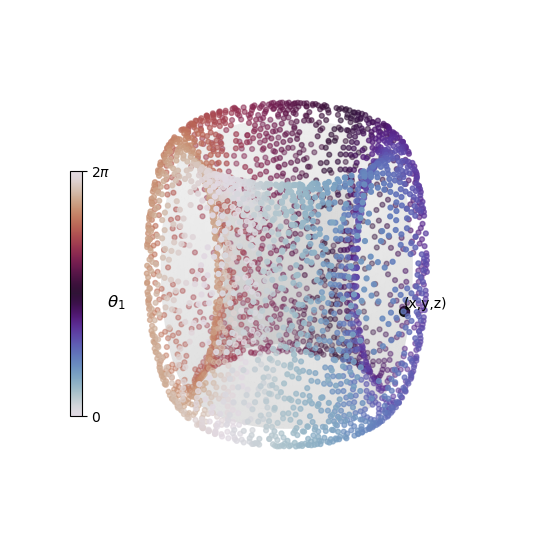

In [4]:
# ============================================================
# Full Torus Mesh + Sampled Trajectory Overlay (No Axes)
# ============================================================

# 1) Build a smooth torus mesh
R0 = np.mean(R_t_og)
r0 = np.mean(r_t_og)

n1, n2 = 120, 60
u = np.linspace(0, 2*np.pi, n1)
v = np.linspace(0, 2*np.pi, n2)
U, V = np.meshgrid(u, v)

scale = 0.9
X_mesh = scale* (R0 + r0 * np.cos(V)) * np.cos(U)
Y_mesh = scale* (R0 + r0 * np.cos(V)) * np.sin(U)
Z_mesh = scale* r0 * np.sin(V)

# 2) Figure
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

# 3) Torus mesh (light grey)
ax.plot_surface(
    X_mesh, Y_mesh, Z_mesh,
    rstride=1, cstride=1,
    color='lightgray', edgecolor='none', alpha=0.1
)

# 4) Sampled trajectory (colored)
sc = ax.scatter(
    x, y, z,
    c=theta1,
    cmap='twilight',
    s=12
)
# (You can switch to max X or custom if you rotate the view)
front_idx = np.argmax(y)    # index of the front-most sample

front_x = x[front_idx]
front_y = y[front_idx]
front_z = z[front_idx]

# Plot a large marker there
ax.scatter(front_x, front_y, front_z,
           color='black', s=80, edgecolors='white', linewidth=0.8,
           zorder=10)

# ------------------------------------------------------------
# 4c) Add text label "(x, y, z)" next to the highlighted point
# ------------------------------------------------------------
label = f"(x,y,z)"

ax.text(
    front_x, front_y, front_z,
    label,
    fontsize=10,
    color='black',
    ha='left', va='bottom',
    zorder=20
)


# ------------------------------------------------------------
# TURN OFF ALL AXIS COMPONENTS
# ------------------------------------------------------------
ax.set_axis_off()
ax.grid(False)

# Remove ticks (matplotlib may still keep some unless forced)
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])

# Remove label text
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_zlabel("")

# Remove title
ax.set_title("")

# Optional: tighten layout for clean view
ax.set_box_aspect([1,1,1])
ax.view_init(25, 35)

# ------------------------------------------------------------
# Colorbar with explicit placement
# ------------------------------------------------------------
sm = plt.cm.ScalarMappable(
    cmap="twilight",
    norm=plt.Normalize(vmin=0, vmax=2*np.pi)
)
sm.set_array([])

cbar_ax = fig.add_axes([0.25, 0.3, 0.015, 0.35])
cbar = fig.colorbar(sm, cax=cbar_ax)

cbar.set_label(r'$\theta_1$', fontsize=12, labelpad=4, rotation=0)
cbar.set_ticks([0, 2*np.pi])
cbar.set_ticklabels([r'$0$', r'$2\pi$'])
cbar.ax.tick_params(labelsize=10)

plt.show()


In [5]:
# -------------------------
# Convert tensors to NumPy for plotting
# -------------------------
A_np = A.cpu().numpy()
B_np = B.cpu().numpy()

# -------------------------
# Plotly interactive torus, two views
# -------------------------
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type': 'scatter3d'}, {'type': 'scatter3d'}]],
    subplot_titles=("Colored by θ₁", "Colored by θ₂")
)

# Plot colored by θ1
fig.add_trace(
    go.Scatter3d(
        x=x, y=y, z=z,
        mode='markers',
        marker=dict(
            size=3,
            color=theta1,   # color by θ1
            colorscale='Viridis',
            showscale=False
        ),
        name="θ1 trajectory"
    ),
    row=1, col=1
)

# Plot colored by θ2
fig.add_trace(
    go.Scatter3d(
        x=x, y=y, z=z,
        mode='markers',
        marker=dict(
            size=3,
            color=theta2,   # color by θ2
            colorscale='Plasma',
            showscale=False
        ),
        name="θ2 trajectory"
    ),
    row=1, col=2
)

fig.update_layout(
    title="Interactive Torus Trajectory (colored by latent angles)",
    scene=dict(aspectmode='data'),
    scene2=dict(aspectmode='data'),
    width=1200, height=600
)

fig.show()


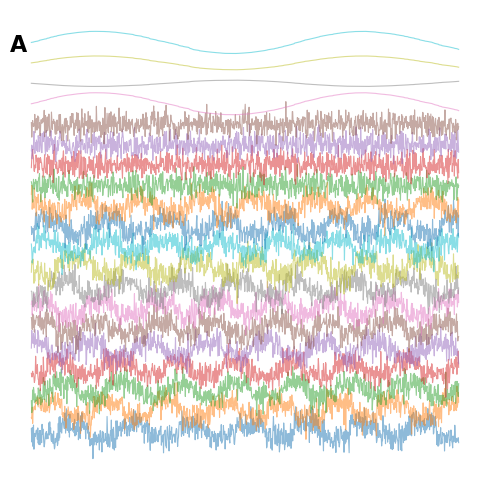

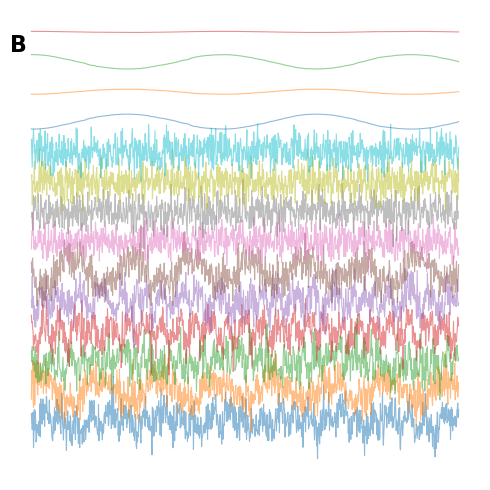

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# Convert to numpy if still torch tensors
A_np = np.asarray(A)
B_np = np.asarray(B)

# ----------------------------------------------------------
# Example time-series window (plot subset for clarity)
# ----------------------------------------------------------
t_window = slice(0, 1000)      # show first 1000 samples
offset_A = 3.0
offset_B = 3.0

# -------------------------
# Modality A (stacked)
# -------------------------
plt.figure(figsize=(5, 5))
for ch in range(A_np.shape[1]):
    plt.plot(A_np[t_window, ch] + ch * offset_A, lw=0.8, alpha = 0.5)
plt.text(0, 0.95, "A", transform=plt.gca().transAxes,
         fontsize=16, fontweight='bold', va='top', ha='left')
plt.axis('off')
plt.tight_layout()
plt.show()

# -------------------------
# Modality B (stacked)
# -------------------------
plt.figure(figsize=(5, 5))
for ch in range(B_np.shape[1]):
    plt.plot(B_np[t_window, ch] + ch * offset_B, lw=0.8,alpha =0.5)
plt.text(0, 0.95, "B", transform=plt.gca().transAxes,
         fontsize=16, fontweight='bold', va='top', ha='left')
plt.axis('off')
plt.tight_layout()
plt.show()




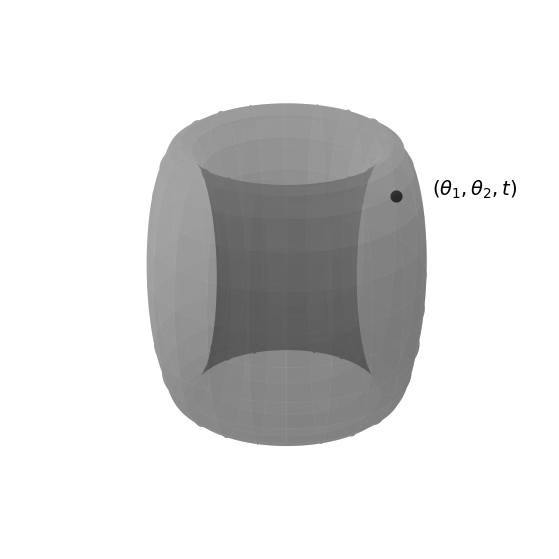

In [5]:
# ============================================================
# Minimal Torus Visualization (only surface + point) — Clean version
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# --- Torus mesh ---
R_vis, r_vis = 3.0, 1.0
n = 120
theta1_mesh = np.linspace(0, 2*np.pi, n)
theta2_mesh = np.linspace(0, 2*np.pi, n)
T1, T2 = np.meshgrid(theta1_mesh, theta2_mesh)

X = (R_vis + r_vis * np.cos(T2)) * np.cos(T1)
Y = (R_vis + r_vis * np.cos(T2)) * np.sin(T1)
Z = r_vis * np.sin(T2)

# --- Example point ---
t1_ex, t2_ex = np.pi / 4, np.pi / 3
x_ex = (R_vis + r_vis * np.cos(t2_ex)) * np.cos(t1_ex)
y_ex = (R_vis + r_vis * np.cos(t2_ex)) * np.sin(t1_ex) + 0.5
z_ex = r_vis * np.sin(t2_ex)

# --- Plot ---
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Torus surface
ax.plot_surface(X, Y, Z, rstride=6, cstride=6,
                color='grey', alpha=0.4, linewidth=0)

# Highlighted point
ax.scatter(x_ex, y_ex, z_ex, color='k', s=60)
ax.text(x_ex, y_ex+1, z_ex,
        r'$(\theta_1, \theta_2, t)$',
        color='k', fontsize=14, fontweight='bold')

# --- Remove all axes, panes, grids, and background ---
ax.set_axis_off()
ax.set_facecolor('none')
fig.patch.set_facecolor('none')

# Hide the 3D panes
for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
    axis.pane.set_visible(False)
    axis.line.set_color((1, 1, 1, 0))   # invisible axes lines

ax.grid(False)

# Camera view
ax.view_init(elev=25, azim=0)
ax.set_box_aspect([1, 1, 1])

plt.show()


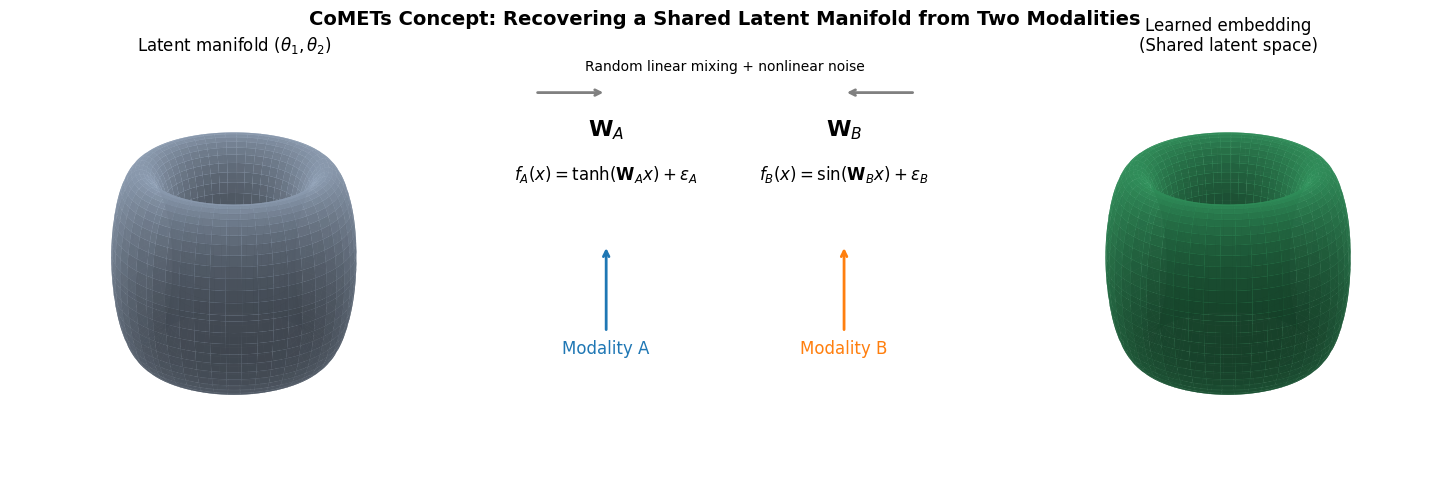

In [6]:
# ============================================================
# Conceptual Pipeline Visualization: Torus → Two Modalities → Embedding
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# --- Torus mesh for base manifold ---
R, r = 3.0, 1.0
n = 100
t1, t2 = np.meshgrid(np.linspace(0, 2*np.pi, n), np.linspace(0, 2*np.pi, n))
X = (R + r * np.cos(t2)) * np.cos(t1)
Y = (R + r * np.cos(t2)) * np.sin(t1)
Z = r * np.sin(t2)

# --- Create figure layout (3D + flow arrows) ---
fig = plt.figure(figsize=(15, 5))

# (1) Latent torus
ax1 = fig.add_subplot(131, projection='3d')
ax1.plot_surface(X, Y, Z, color='lightsteelblue', alpha=0.9, linewidth=0)
ax1.text(0, 0, 2.2, r'Latent manifold $(\theta_1, \theta_2)$',
         color='k', fontsize=12, ha='center')
ax1.view_init(elev=25, azim=40)
ax1.set_axis_off()

# (2) Two noisy transformations (concept)
ax2 = fig.add_subplot(132)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1)
ax2.axis('off')

# Random matrices (LaTeX)
ax2.text(0.25, 0.8, r'$\mathbf{W}_A$', fontsize=16, ha='center')
ax2.text(0.25, 0.7, r'$f_A(x) = \tanh(\mathbf{W}_A x) + \epsilon_A$', fontsize=12, ha='center')
ax2.text(0.75, 0.8, r'$\mathbf{W}_B$', fontsize=16, ha='center')
ax2.text(0.75, 0.7, r'$f_B(x) = \sin(\mathbf{W}_B x) + \epsilon_B$', fontsize=12, ha='center')

# arrows to indicate flow
ax2.annotate("", xy=(0.25, 0.55), xytext=(0.25, 0.35),
             arrowprops=dict(arrowstyle="->", lw=2, color='tab:blue'))
ax2.annotate("", xy=(0.75, 0.55), xytext=(0.75, 0.35),
             arrowprops=dict(arrowstyle="->", lw=2, color='tab:orange'))

ax2.text(0.25, 0.3, "Modality A", fontsize=12, color='tab:blue', ha='center')
ax2.text(0.75, 0.3, "Modality B", fontsize=12, color='tab:orange', ha='center')

# arrows from torus to transformations
ax2.annotate("", xy=(0.25, 0.9), xytext=(0.1, 0.9),
             arrowprops=dict(arrowstyle="->", lw=2, color='gray'))
ax2.annotate("", xy=(0.75, 0.9), xytext=(0.9, 0.9),
             arrowprops=dict(arrowstyle="->", lw=2, color='gray'))
ax2.text(0.5, 0.95, "Random linear mixing + nonlinear noise", fontsize=10, ha='center')

# (3) Learned embedding (recovered torus)
ax3 = fig.add_subplot(133, projection='3d')
ax3.plot_surface(X, Y, Z, color='mediumseagreen', alpha=0.9, linewidth=0)
ax3.text(0, 0, 2.2, "Learned embedding\n(Shared latent space)", color='k',
         fontsize=12, ha='center')
ax3.view_init(elev=25, azim=40)
ax3.set_axis_off()

# Overall title
fig.suptitle("CoMETs Concept: Recovering a Shared Latent Manifold from Two Modalities",
             fontsize=14, fontweight='bold', y=0.98)

plt.tight_layout()
plt.show()
